In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, accuracy_score
import joblib

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("Iris.csv")

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSpecies Count:")
print(df['Species'].value_counts())

Dataset Shape: (150, 6)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB

Missing Values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Species Count:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [5]:
# Remove unnecessary columns
X = df.drop(['Id', 'Species'], axis=1)

# Store actual species labels
y = df['Species']

print("Features selected:")
print(X.head())

print("\nDataset shape:", X.shape)

Features selected:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2

Dataset shape: (150, 4)


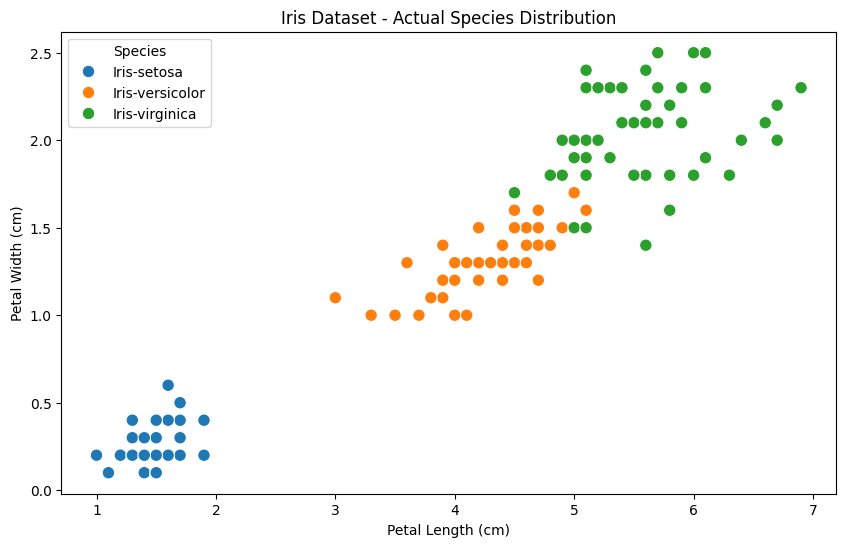

In [6]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='PetalLengthCm',
    y='PetalWidthCm',
    hue='Species',
    s=80
)

plt.title("Iris Dataset - Actual Species Distribution")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")

plt.show()

In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed successfully!")

print("\nScaled Data:")
print(X_scaled[:5])

Feature scaling completed successfully!

Scaled Data:
[[-0.90068117  1.03205722 -1.3412724  -1.31297673]
 [-1.14301691 -0.1249576  -1.3412724  -1.31297673]
 [-1.38535265  0.33784833 -1.39813811 -1.31297673]
 [-1.50652052  0.10644536 -1.2844067  -1.31297673]
 [-1.02184904  1.26346019 -1.3412724  -1.31297673]]


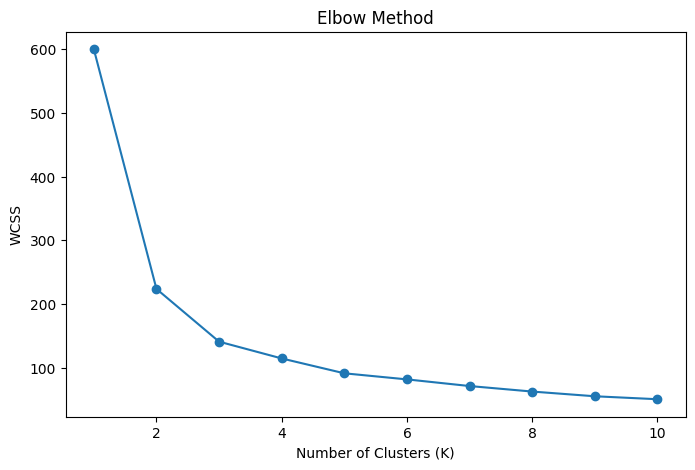

In [8]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")

plt.show()

In [9]:
kmeans = KMeans(
    n_clusters=3,
    init='k-means++',
    random_state=42,
    n_init=10
)

# Train the model
kmeans.fit(X_scaled)

# Predict clusters
y_kmeans = kmeans.predict(X_scaled)

print("K-Means clustering completed successfully!")
print("\nCluster Distribution:")
print(pd.Series(y_kmeans).value_counts().sort_index())

K-Means clustering completed successfully!

Cluster Distribution:
0    53
1    50
2    47
Name: count, dtype: int64


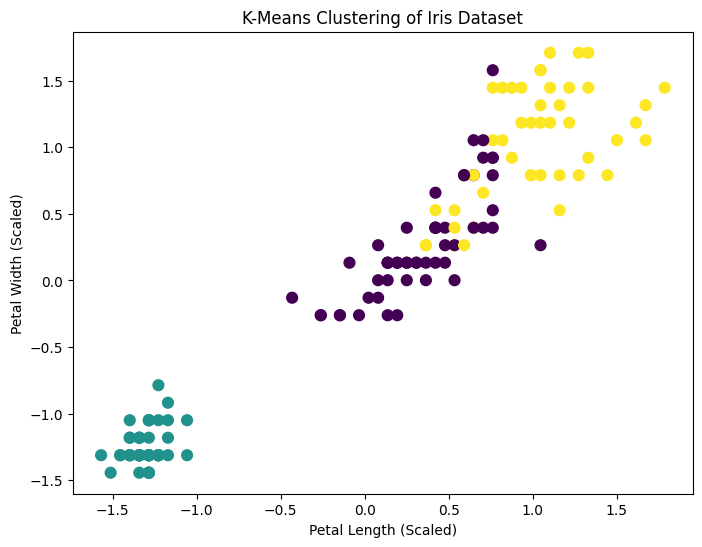

In [10]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 2],
    X_scaled[:, 3],
    c=y_kmeans,
    cmap='viridis',
    s=60
)

plt.title("K-Means Clustering of Iris Dataset")
plt.xlabel("Petal Length (Scaled)")
plt.ylabel("Petal Width (Scaled)")

plt.show()

In [12]:
comparison = pd.DataFrame({
    'Actual Species': y,
    'Predicted Cluster': y_kmeans
})

print(comparison.head(15))

   Actual Species  Predicted Cluster
0     Iris-setosa                  1
1     Iris-setosa                  1
2     Iris-setosa                  1
3     Iris-setosa                  1
4     Iris-setosa                  1
5     Iris-setosa                  1
6     Iris-setosa                  1
7     Iris-setosa                  1
8     Iris-setosa                  1
9     Iris-setosa                  1
10    Iris-setosa                  1
11    Iris-setosa                  1
12    Iris-setosa                  1
13    Iris-setosa                  1
14    Iris-setosa                  1


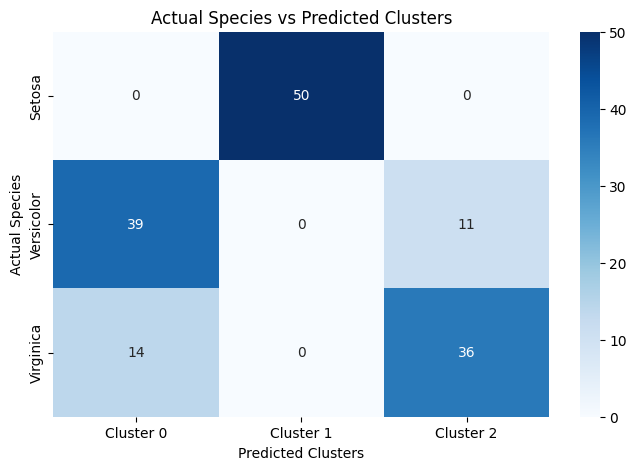

In [14]:
from sklearn.metrics import confusion_matrix

# Convert actual species names into numerical labels
actual_labels = pd.factorize(y)[0]

# Create confusion matrix
cm = confusion_matrix(actual_labels, y_kmeans)

plt.figure(figsize=(8, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Cluster 0', 'Cluster 1', 'Cluster 2'],
    yticklabels=['Setosa', 'Versicolor', 'Virginica']
)

plt.title("Actual Species vs Predicted Clusters")
plt.xlabel("Predicted Clusters")
plt.ylabel("Actual Species")

plt.show()

In [15]:
from sklearn.decomposition import PCA

# Apply PCA
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original Dimensions:", X_scaled.shape)
print("Reduced Dimensions:", X_pca.shape)

print("Explained Variance Ratio:", pca.explained_variance_ratio_)

print("Total Variance Retained:",
      sum(pca.explained_variance_ratio_) * 100, "%")

Original Dimensions: (150, 4)
Reduced Dimensions: (150, 2)
Explained Variance Ratio: [0.72770452 0.23030523]
Total Variance Retained: 95.80097536148196 %


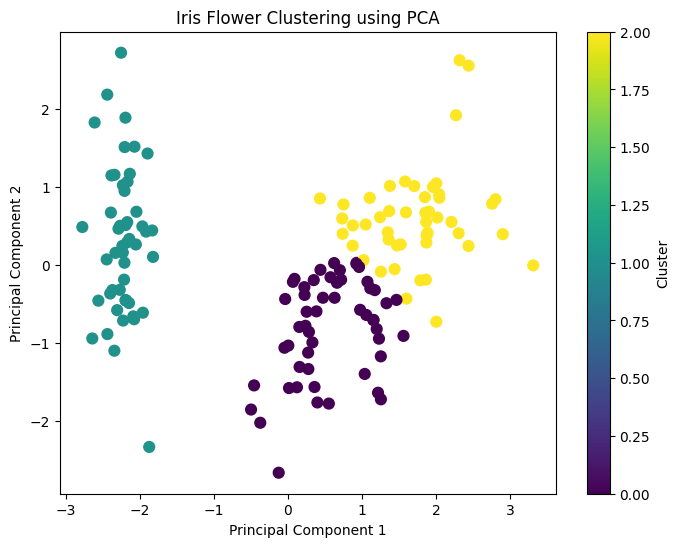

In [16]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y_kmeans,
    cmap='viridis',
    s=60
)

plt.title("Iris Flower Clustering using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(label="Cluster")
plt.show()

In [17]:
import joblib

joblib.dump(kmeans, 'kmeans_iris_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(pca, 'pca_model.pkl')

print("All models saved successfully!")

All models saved successfully!


In [18]:
# Load saved models
loaded_model = joblib.load('kmeans_iris_model.pkl')
loaded_scaler = joblib.load('scaler.pkl')
loaded_pca = joblib.load('pca_model.pkl')

# Select one sample
sample = X.iloc[[0]]

# Scale sample
sample_scaled = loaded_scaler.transform(sample)

# Predict cluster
prediction = loaded_model.predict(sample_scaled)

# Apply PCA
sample_pca = loaded_pca.transform(sample_scaled)

print("Predicted Cluster:", prediction[0])
print("PCA Transformed Sample:", sample_pca)

Predicted Cluster: 1
PCA Transformed Sample: [[-2.26454173  0.5057039 ]]
